In [1]:
from pathlib import Path
import time

print("1. Locating saved model...", flush=True)

models = list(Path("/kaggle/input").rglob("best_model.keras"))

if len(models) != 1:
    raise RuntimeError(f"Expected one model, found: {models}")

best_model_path = models[0]
print("Model size (MB):", round(best_model_path.stat().st_size / 1e6, 2))
print("2. Importing TensorFlow...", flush=True)

import tensorflow as tf

print("TensorFlow:", tf.__version__, flush=True)
print("3. Loading model on CPU...", flush=True)

start = time.perf_counter()

with tf.device("/CPU:0"):
    best_model = tf.keras.models.load_model(
        best_model_path,
        compile=False,
    )

print("4. Model loaded successfully.", flush=True)
print("Load time (seconds):", round(time.perf_counter() - start, 2))
print("Input shape:", best_model.input_shape)
print("Output shape:", best_model.output_shape)

1. Locating saved model...
Model size (MB): 1.29
2. Importing TensorFlow...
TensorFlow: 2.20.0
3. Loading model on CPU...


2026-10-18 20:53:39.518831: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


4. Model loaded successfully.
Load time (seconds): 0.35
Input shape: (None, 224, 224, 1)
Output shape: (None, 1)


In [2]:
import numpy as np

# Synthetic input checks execution, not diagnostic accuracy.
sample = np.zeros((1, 224, 224, 1), dtype=np.float32)

with tf.device("/CPU:0"):
    output = best_model(sample, training=False).numpy()

assert output.shape == (1, 1)
assert np.isfinite(output).all()
assert ((output >= 0) & (output <= 1)).all()

print("CPU inference check passed.")
print("Output shape:", output.shape)

CPU inference check passed.
Output shape: (1, 1)


In [3]:
from pathlib import Path
import hashlib
import importlib
import sys
import time
import pandas as pd
import numpy as np

INPUT_DIR = Path("/kaggle/input")


def find_one(filename):
    matches = list(INPUT_DIR.rglob(filename))

    if len(matches) != 1:
        raise RuntimeError(
            f"Expected one {filename}, found {len(matches)}: {matches}"
        )

    return matches[0]


dataset_dir = find_one("train.txt").parent

expected_hashes = {
    "train.txt": (
        "52af9a4fdc769396bc5ce530872cf0d51bce"
        "8fd7e25579b333007d4ebee6a6ba"
    ),
    "test.txt": (
        "7c92ae0bef49652005e1541a1f2b774e31"
        "3be4431a891cb0aa5539d37ca2a71e"
    ),
}

for filename, expected in expected_hashes.items():
    actual = hashlib.sha256(
        (dataset_dir / filename).read_bytes()
    ).hexdigest()
    assert actual == expected, f"Label mismatch: {filename}"

validation = pd.read_csv(
    find_one("validation.csv"),
    dtype=str,
    keep_default_na=False,
)

assert len(validation) == 6103
assert validation["filename"].is_unique
assert set(validation["label"]) == {"negative", "positive"}

module_files = list(INPUT_DIR.glob("**/src/covid_xray/data.py"))
assert len(module_files) == 1, module_files

sys.path.insert(0, str(module_files[0].parents[1]))
importlib.invalidate_caches()

from covid_xray.data import make_dataset

val_ds = make_dataset(
    validation,
    image_dir=dataset_dir / "train",
    batch_size=32,
    training_mode=False,
)

print("Dataset verified. Loading one validation batch...", flush=True)
start = time.perf_counter()

images, labels = next(iter(val_ds))

with tf.device("/CPU:0"):
    scores = best_model(images, training=False).numpy()

assert scores.shape == (32, 1)
assert np.isfinite(scores).all()
assert ((scores >= 0) & (scores <= 1)).all()

print("Real validation batch inference passed.")
print("Images:", images.shape)
print("Scores:", scores.shape)
print("Elapsed seconds:", round(time.perf_counter() - start, 2))

Dataset verified. Loading one validation batch...
Real validation batch inference passed.
Images: (32, 224, 224, 1)
Scores: (32, 1)
Elapsed seconds: 2.12


In [4]:
import json
import time
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss,
)

all_labels = []
all_scores = []
start = time.perf_counter()

for batch_number, (images, labels) in enumerate(val_ds, start=1):
    with tf.device("/CPU:0"):
        scores = best_model(images, training=False).numpy().ravel()

    assert np.isfinite(scores).all()
    assert ((scores >= 0) & (scores <= 1)).all()

    all_labels.append(labels.numpy().ravel())
    all_scores.append(scores)

    if batch_number % 20 == 0:
        print(
            f"Checked {batch_number}/191 batches",
            flush=True,
        )

y_true = np.concatenate(all_labels).astype(int)
y_score = np.concatenate(all_scores)

expected_labels = (
    validation["label"]
    .map({"negative": 0, "positive": 1})
    .to_numpy(dtype=int)
)

np.testing.assert_array_equal(y_true, expected_labels)
assert len(y_score) == 6103

# Match Keras's default binary metric threshold convention.
y_pred = (y_score > 0.5).astype(int)

validation_metrics = {
    "images": int(len(y_true)),
    "threshold": 0.5,
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "precision": float(precision_score(y_true, y_pred, zero_division=0)),
    "recall": float(recall_score(y_true, y_pred, zero_division=0)),
    "f1": float(f1_score(y_true, y_pred, zero_division=0)),
    "roc_auc": float(roc_auc_score(y_true, y_score)),
    "log_loss": float(log_loss(y_true, y_score, labels=[0, 1])),
    "seconds": round(time.perf_counter() - start, 2),
}

results_dir = Path("/kaggle/working/artifacts/results")
results_dir.mkdir(parents=True, exist_ok=True)

(results_dir / "best_validation_metrics.json").write_text(
    json.dumps(validation_metrics, indent=2),
    encoding="utf-8",
)

print("\nSaved best model — validation results:")
print(json.dumps(validation_metrics, indent=2))

Checked 20/191 batches
Checked 40/191 batches
Checked 60/191 batches
Checked 80/191 batches
Checked 100/191 batches
Checked 120/191 batches
Checked 140/191 batches
Checked 160/191 batches
Checked 180/191 batches

Saved best model — validation results:
{
  "images": 6103,
  "threshold": 0.5,
  "accuracy": 0.8990660330984762,
  "precision": 0.9238787113076438,
  "recall": 0.8863636363636364,
  "f1": 0.9047324466439839,
  "roc_auc": 0.9571819695348058,
  "log_loss": 0.29161081685433743,
  "seconds": 251.36
}


In [5]:
from sklearn.metrics import confusion_matrix, classification_report

# Load the unchanged official test labels.
test_path = dataset_dir / "test.txt"

test_rows = [
    line.split()
    for line in test_path.read_text(encoding="utf-8-sig").splitlines()
    if line.strip()
]

assert all(len(row) == 4 for row in test_rows)

test_table = pd.DataFrame(
    test_rows,
    columns=["patient_id", "filename", "label", "source"],
)

assert len(test_table) == 400
assert test_table["filename"].is_unique
assert test_table["label"].value_counts().to_dict() == {
    "positive": 200,
    "negative": 200,
}

missing = [
    filename for filename in test_table["filename"]
    if not (dataset_dir / "test" / filename).is_file()
]
assert not missing, f"Missing test images: {missing[:5]}"

test_ds = make_dataset(
    test_table,
    image_dir=dataset_dir / "test",
    batch_size=32,
    training_mode=False,
)

test_labels = []
test_scores = []

for batch_number, (images, labels) in enumerate(test_ds, start=1):
    with tf.device("/CPU:0"):
        scores = best_model(images, training=False).numpy().ravel()

    assert np.isfinite(scores).all()
    assert ((scores >= 0) & (scores <= 1)).all()

    test_labels.append(labels.numpy().ravel())
    test_scores.append(scores)
    print(f"Test batch {batch_number}/13 completed", flush=True)

test_y_true = np.concatenate(test_labels).astype(int)
test_y_score = np.concatenate(test_scores)

expected = test_table["label"].map(
    {"negative": 0, "positive": 1}
).to_numpy(dtype=int)

np.testing.assert_array_equal(test_y_true, expected)
assert len(test_y_score) == 400

# Keep the threshold fixed before inspecting test results.
test_y_pred = (test_y_score > 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(
    test_y_true, test_y_pred, labels=[0, 1]
).ravel()

test_metrics = {
    "images": 400,
    "threshold": 0.5,
    "accuracy": float(accuracy_score(test_y_true, test_y_pred)),
    "precision": float(
        precision_score(test_y_true, test_y_pred, zero_division=0)
    ),
    "recall": float(
        recall_score(test_y_true, test_y_pred, zero_division=0)
    ),
    "f1": float(f1_score(test_y_true, test_y_pred, zero_division=0)),
    "roc_auc": float(roc_auc_score(test_y_true, test_y_score)),
    "log_loss": float(
        log_loss(test_y_true, test_y_score, labels=[0, 1])
    ),
    "true_negative": int(tn),
    "false_positive": int(fp),
    "false_negative": int(fn),
    "true_positive": int(tp),
}

(results_dir / "test_metrics.json").write_text(
    json.dumps(test_metrics, indent=2),
    encoding="utf-8",
)

report = classification_report(
    test_y_true,
    test_y_pred,
    labels=[0, 1],
    target_names=["negative", "positive"],
    output_dict=True,
    zero_division=0,
)

pd.DataFrame(report).T.to_csv(
    results_dir / "test_classification_report.csv"
)

print("\nOfficial test results:")
print(json.dumps(test_metrics, indent=2))

Test batch 1/13 completed
Test batch 2/13 completed
Test batch 3/13 completed
Test batch 4/13 completed
Test batch 5/13 completed
Test batch 6/13 completed
Test batch 7/13 completed
Test batch 8/13 completed
Test batch 9/13 completed
Test batch 10/13 completed
Test batch 11/13 completed
Test batch 12/13 completed
Test batch 13/13 completed

Official test results:
{
  "images": 400,
  "threshold": 0.5,
  "accuracy": 0.785,
  "precision": 0.88,
  "recall": 0.66,
  "f1": 0.7542857142857143,
  "roc_auc": 0.9055,
  "log_loss": 0.48621377020169687,
  "true_negative": 182,
  "false_positive": 18,
  "false_negative": 68,
  "true_positive": 132
}


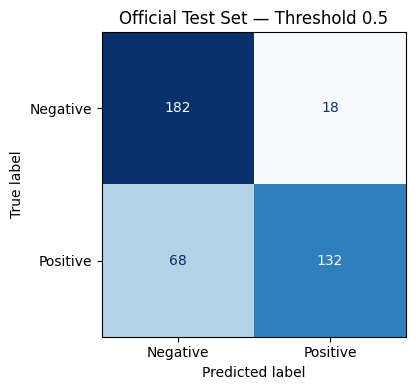

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

matrix = confusion_matrix(
    test_y_true,
    test_y_pred,
    labels=[0, 1],
)

fig, ax = plt.subplots(figsize=(5, 4))

display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=["Negative", "Positive"],
)
display.plot(ax=ax, cmap="Blues", colorbar=False)

ax.set_title("Official Test Set — Threshold 0.5")
fig.tight_layout()

fig.savefig(
    results_dir / "test_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

In [7]:
from IPython.display import FileLink, display

for filename in [
    "test_metrics.json",
    "test_classification_report.csv",
    "test_confusion_matrix.png",
]:
    path = results_dir / filename

    if not path.is_file():
        raise FileNotFoundError(path)

    display(
        FileLink(
            str(path.relative_to("/kaggle/working"))
        )
    )

/kaggle/working/artifacts/results/test_metrics.json

/kaggle/working/artifacts/results/test_classification_report.csv

/kaggle/working/artifacts/results/test_confusion_matrix.png